# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [2]:
# votre code
df=pd.read_csv("data/comptage-velos.csv",sep=";")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 18.8 KB


La colonne date est du type "str" donc chaîne de caractère. Pas satisfaisant car on peut pas faire d'opérations élémentaires sur ces dates. Le fichier n'est pas trié par date comme on l'observe dans le csv et 734 lignes>731 jours en 2 ans

In [3]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [4]:
# votre code
df["date"]=pd.to_datetime(df["date"], format="%Y-%m-%d")
#cf p59 du cours, on convertit nos str en datetime64 quon pourra trié

brut = df.set_index("date")["comptage"].sort_index()
#cf p61,on dit que date est maintenant l'index, et comme le dtype est maintenant datetime64 , trié les dates a du sens
brut

date
2023-01-01     304.0
2023-01-02    1658.0
2023-01-03    1450.0
2023-01-04    1902.0
2023-01-05    1715.0
               ...  
2024-12-27    1906.0
2024-12-28    1186.0
2024-12-29    1040.0
2024-12-30    1900.0
2024-12-31    2126.0
Name: comptage, Length: 734, dtype: float64

In [5]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [6]:
# votre code
nombre_doubles=sum(brut.index.duplicated())
#on utilise les index de brut qui sont les dates, True valent 1, False 0 donc la somme donne le nombre
liste_dates= brut.index[brut.index.duplicated()].unique() #on crée un masque et on selectionne les valeurs unique
print("Q1 :il y a:",sum(brut.index.duplicated()),"dates qui aparaissent en double",liste_dates)

nombre_manquant=brut.isna().sum()#compte direct les valeurs manquantes
liste_vm=brut.index[brut.isna()] #on selectionne des DATES donc l'index de la série
print("Q2: il manque :",nombre_manquant,"dates et c'est",liste_vm)

print("Q3: les jours dont le comptage est nul :",brut.index[brut==0])
print("Q4 : les jours dont le comptage dépasse 3xmediane:",brut.index[brut>3*brut.median()])


Q1 :il y a: 3 dates qui aparaissent en double DatetimeIndex(['2023-05-25', '2023-12-21', '2024-02-27'], dtype='datetime64[us]', name='date', freq=None)
Q2: il manque : 8 dates et c'est DatetimeIndex(['2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09',
               '2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22'],
              dtype='datetime64[us]', name='date', freq=None)
Q3: les jours dont le comptage est nul : DatetimeIndex(['2024-06-27'], dtype='datetime64[us]', name='date', freq=None)
Q4 : les jours dont le comptage dépasse 3xmediane: DatetimeIndex(['2024-07-04'], dtype='datetime64[us]', name='date', freq=None)



* **3 dates** apparaissent deux fois dans le fichier :
  * `2023-05-25`
  * `2023-12-21`
  * `2024-02-27`

*  Il manque **8 mesures** dans la colonne comptage :
  * `2023-02-23`, `2023-06-25`, `2023-12-01`
  * `2024-01-09`, `2024-02-08`, `2024-03-13`, `2024-11-17`, `2024-11-22`


  * **Comptage nul (0 vélo) :** Le `2024-06-27`
  * **Comptage extrême (> 3 × médiane) :** Le `2024-07-04` avec un pic mesuré à **39 660 vélos** (valeur aberrante)



In [7]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [8]:
# votre code
velos=brut[~brut.index.duplicated()].copy()
#cf l'énoncé de 1.b, on fait copy pour modifie cette série 
velos[(velos == 0) | (velos > 3 * velos.median())]=np.nan
#on utilise un masque
velos=velos.interpolate()

In [9]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [10]:
# votre code
hebdo=velos.resample("W").mean() 
mensuel=velos.resample("ME").mean()
annuel=velos.resample("YE").mean()
#cf p63 du cours
print("hebdo,mensuel ont respectivement:",len(hebdo),"et",len(mensuel),'lignes')

hebdo,mensuel ont respectivement: 106 et 24 lignes


**731/7** n'est pas un entier, de plus le 1er janvier 2023 c'est un dimanche et le 31 décembre c'est un mardi donc il y a des mi-semaines.

In [11]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

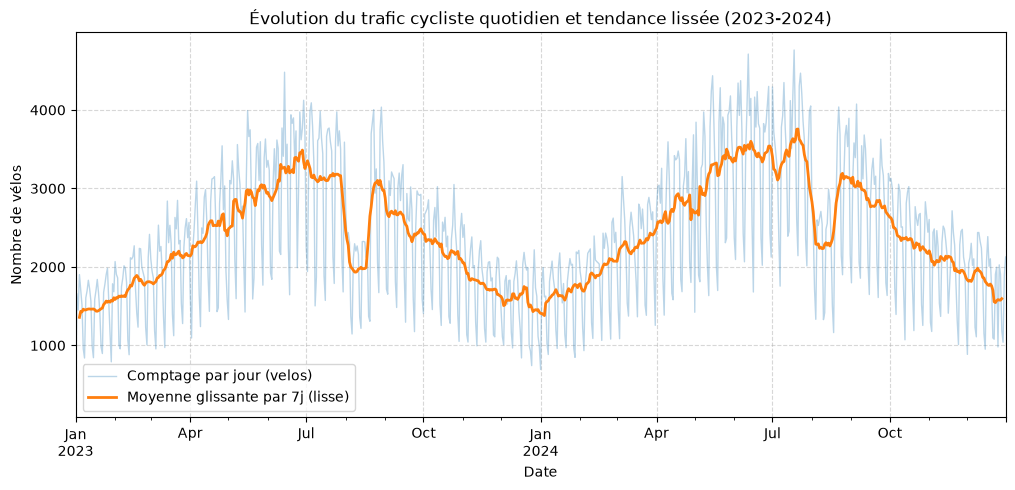

In [12]:
# votre code
lisse=velos.rolling(7,center=True).mean()

axe = velos.plot(figsize=(12, 5), alpha=0.3, linewidth=1, label="Comptage par jour (velos)")
lisse.plot(ax=axe, linewidth=2, label="Moyenne glissante par 7j (lisse)")
#figsize fixe la taille, alpha la transparence,linewidth lepaisseur du trait
plt.title("Évolution du trafic cycliste quotidien et tendance lissée (2023-2024)")
plt.xlabel("Date")
plt.ylabel("Nombre de vélos")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)#on paramètre la grille

plt.show()

-Lisse contient 6 valeurs NaN, les 3 premier jours car on a pas 3 jours avant pour les centrées de faire leur moyenne glissante.Idem pour les 3 derniers.\
-7 c'est une semaine c'est un cycle hebdomadaire et prend en compte semaine+weekend donc bon compromis pour lisser les données


In [13]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [14]:
# votre code
profil_semaine=velos.groupby(velos.index.dayofweek).mean()
#cf p65
jours= ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
profil_semaine.index = jours#on renomme les index
moyenne_semaine=profil_semaine.loc["lun":"ven"].mean()
#on selectionne ici les valeurs par les indices avec .loc
pourcentage=100*(moyenne_semaine-profil_semaine.loc["dim"])/moyenne_semaine
#on calcul un écart relatif
print("le dimanche est:",pourcentage.round(1),"% plus bas que la moyenne de la semaine")

le dimanche est: 49.8 % plus bas que la moyenne de la semaine


In [15]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

In [16]:
# votre code
profil_mois=velos.groupby(velos.index.month).mean()
#on fait la meme chose qu'avant

mois_charge=profil_mois.idxmax() #l'étiquette est le mois
print("le mois le plus chargé est le :",mois_charge,"ème mois de l''année")

le mois le plus chargé est le : 6 ème mois de l''année


On voit mai , juin, juillet très haut(~3100-3200) et une chute en août(~2500). Surement liée au fait que les parisiens partent en vacance dans le sud (envahissent le sud)

In [17]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

In [18]:
# votre code
moyenne_2023=velos.loc["2023"].mean()
moyenne_2024=velos.loc["2024"].mean()
croissance=((moyenne_2024 - moyenne_2023) / moyenne_2023) * 100
print("la moyenne journalière en 2023,2024 est:",moyenne_2023,"et",moyenne_2023)
print("le taux de croissance est:",croissance.round(1),"%")
#on fait la même chose que precedemment.

par_mois = velos.groupby([velos.index.month, velos.index.year]).mean().unstack()
# On regroupe par année avec velos.index.year et par mois velos.index.month
#unstack() pivote le niveau 'année' en colonnes cf p65 du cours

croissance_mensuelle = ((par_mois[2024] - par_mois[2023]) / par_mois[2023]) * 100
mois_forte_progression = croissance_mensuelle.idxmax()
taux_max = croissance_mensuelle.max()
#on refait ce qu'on a fait etapes par etapes dans les questions précédentes
print("le mois où la progression a été la plus forte est le :",mois_forte_progression,"ème mois de l'année avec un taux de :",taux_max.round(1),"%")


la moyenne journalière en 2023,2024 est: 2285.9835616438354 et 2285.9835616438354
le taux de croissance est: 10.5 %
le mois où la progression a été la plus forte est le : 4 ème mois de l'année avec un taux de : 16.0 %


In [19]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

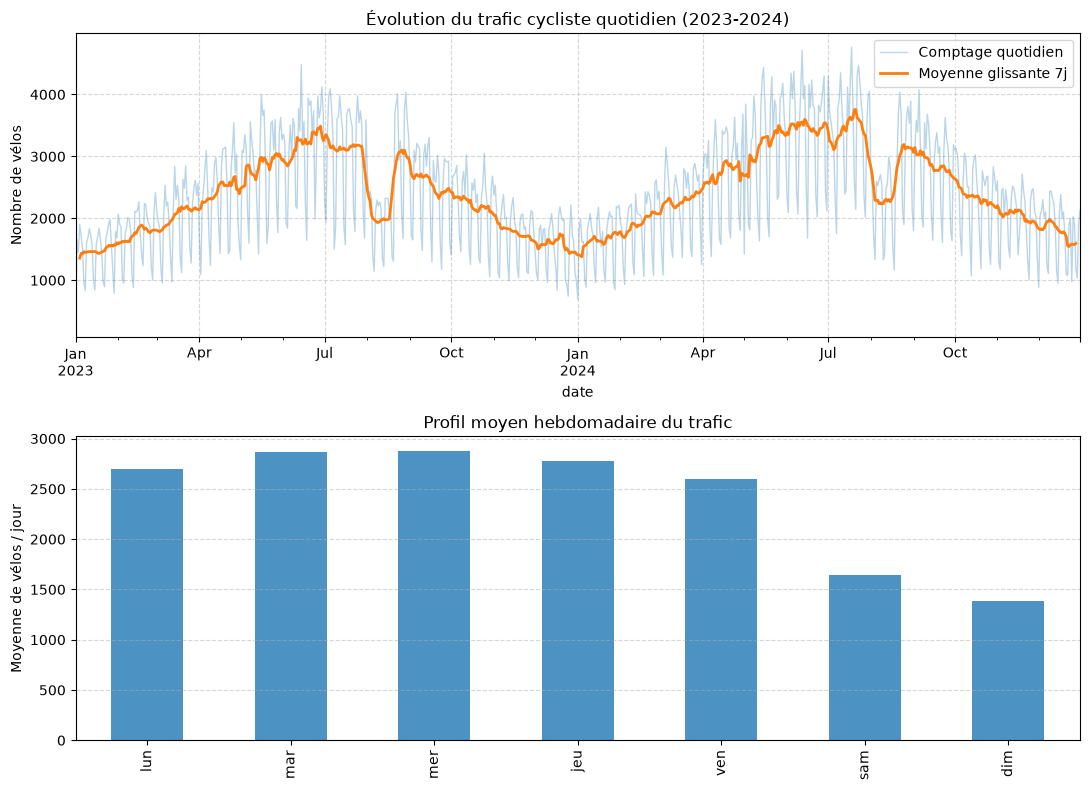

In [20]:
# votre code
#on crée la figure
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))

# Sous-graphique( cf p69-70) du haut,on la deja fait precedement jai fait ctrl c ctr v
velos.plot(ax=ax_haut, alpha=0.3, linewidth=1, label="Comptage quotidien")
lisse.plot(ax=ax_haut, linewidth=2, label="Moyenne glissante 7j")


ax_haut.set_title("Évolution du trafic cycliste quotidien (2023-2024)")
ax_haut.set_ylabel("Nombre de vélos")
ax_haut.legend()
ax_haut.grid(True, linestyle="--", alpha=0.5)

# Sous-graphique du bas en barre donc 
profil_semaine.plot.bar(ax=ax_bas, alpha=0.8)

ax_bas.set_title("Profil moyen hebdomadaire du trafic")
ax_bas.set_ylabel("Moyenne de vélos / jour")
ax_bas.set_xticklabels(["lun", "mar", "mer", "jeu", "ven", "sam", "dim"])
ax_bas.grid(True, axis="y", linestyle="--", alpha=0.5)

fig.tight_layout()#pour pas couper la legende
fig.savefig("serie.png", dpi=300) 

plt.show()

In [21]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

**Questions:quelle semaine de l’année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?**\
Méthode: on s'inspire de ce qu'on a fait déja précedemment : \
1)on calcule les moyennes par semaines chaque année avec resample \
2)on change un peu les indices pour faciliter et on repère max et min,valeur max et valeur min \
3)on trace tout ça


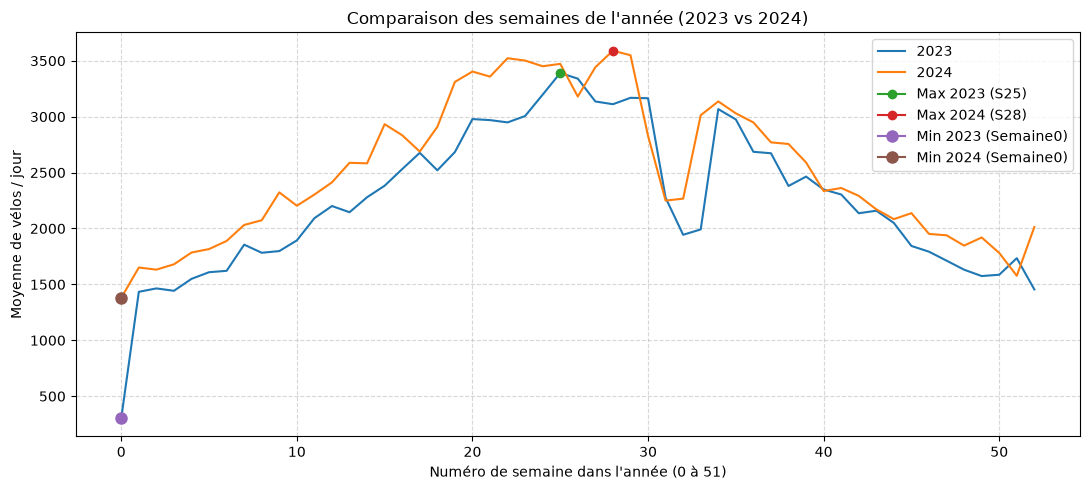

La semaine max 2023 est: 25  avec 3390.7 v/j
La semaine min 2023 est: 0  avec 304.0 v/j
La semaine max 2024 est: 28  avec 3589.9 v/j
La semaine min 2024 est: 0  avec 1379.714 v/j


In [22]:

# On mixe la 3.c et la 2.a pour calculer les moyennes par semaines pour chaque année
moy_hebdo_2023 = velos.loc["2023"].resample("W").mean()
moy_hebdo_2024 = velos.loc["2024"].resample("W").mean()

# je passe l'index en numéros de semaine (0 à 51) pour pouvoir superposer les 2 courbes sinon on a deux courbes qui se suivent et 
#on a un peu plus de mal a comparé les 2 maximas en fonction de la semaine de l'année , donc on reset_index(cf p48 du cours)
hebdo_2023_num = moy_hebdo_2023.reset_index(drop=True)
hebdo_2024_num = moy_hebdo_2024.reset_index(drop=True)

# On calcul les semaines extrêmes (index 0 à 51)
sem_max_2023, sem_min_2023 = hebdo_2023_num.idxmax(), hebdo_2023_num.idxmin()
sem_max_2024, sem_min_2024 = hebdo_2024_num.idxmax(), hebdo_2024_num.idxmin()

#On trace le graphe(cf p66 pour la ref du cours d'ailleurs)
fig, ax = plt.subplots(figsize=(11, 5))
#j'ai testé un peu toute les combinaisons autour de (12,5) habituelle et (11,5) est pas mal
hebdo_2023_num.plot(ax=ax, label="2023")
hebdo_2024_num.plot(ax=ax, label="2024")

#On place les points remarquables sur la courbe pour plus de visibilité !!!
plt.plot(sem_max_2023, hebdo_2023_num.max(), marker='o', label=f'Max 2023 (S{sem_max_2023})')
plt.plot(sem_max_2024, hebdo_2024_num.max(), marker='o', label=f'Max 2024 (S{sem_max_2024})')
#on utilise les f strings sinon c'est la galère pour les variables

# de même pour les minimaux
plt.plot(sem_min_2023, hebdo_2023_num.min(), marker='o', markersize=8, label=f'Min 2023 (Semaine{sem_min_2023})')
plt.plot(sem_min_2024, hebdo_2024_num.min(), marker='o', markersize=8, label=f'Min 2024 (Semaine{sem_min_2024})')
#je sais pas trop comment mettre le légende directement sur les points
#et ce que j'ai vu sur internet ma un peu dépassé donc c'est pas optimal mais bon

# legende et ttitre
ax.set_title("Comparaison des semaines de l'année (2023 vs 2024)")
ax.set_xlabel("Numéro de semaine dans l'année (0 à 51)")
ax.set_ylabel("Moyenne de vélos / jour")
ax.legend()  # Place la légende à côté pour ne pas masquer les courbes
ax.grid(True, linestyle="--", alpha=0.5)

fig.tight_layout()
plt.show()
print("La semaine max 2023 est:",sem_max_2023," avec",hebdo_2023_num.max().round(1),"v/j")
print("La semaine min 2023 est:",sem_min_2023," avec",hebdo_2023_num.min().round(3),"v/j")
print("La semaine max 2024 est:",sem_max_2024," avec",hebdo_2024_num.max().round(1),"v/j")
print("La semaine min 2024 est:",sem_min_2024," avec",hebdo_2024_num.min().round(3),"v/j")

**Conclusion** \
-La semaines la moins chargé est la première semaine de janvier pour les 2 années. \
=>Fête du nouvelle an/vacance/les gens décuvent...\
=>En 2023 il y a 10 fois moins de vélo tout de même, peut être à cause du covid. \
-La semaine la plus chargé en 2023 (lundi 19 juin 2023 au dimanche 25 juin 2023),avec 3390.7 v/j, cohérent, début d'été les gens prennent l'air.\
-La semaine la plus chargé en 2024 (lundi 8 juillet 2024 au dimanche 14 juillet 2024),avec 3589.9 v/j, cohérent aussi, le décalage de 3 semaines c'etait surement les JO.






## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

**Bo.1**

In [23]:
# jour + creux
date_minimum = velos.idxmin()
#on la fait 100 fois...

# jour + chargé
date_maximum = velos.idxmax()

print("le jour le plus creux de la série est:",date_minimum.day_name(),date_minimum.date())
print("le jour le plus chargé de la série est:",date_maximum.day_name(),date_maximum.date())
#j'ai trouvé le .date() sur internet pour eviter de sommer les date_minimum.day+dte_minimum.month etc

le jour le plus creux de la série est: Sunday 2023-01-01
le jour le plus chargé de la série est: Thursday 2024-07-18


L'explication est la même que le bonus ( même pas fait exprès), d'un coté vacances + hiver et de l'autre JO de paris

**Bo.2**

In [24]:
# calcul les totaux annuel cf P65 cours
annuel = velos.groupby(velos.index.year).sum()

#croissance annuelle 
croissance_annuelle = ((annuel[2024] - annuel[2023]) / annuel[2023]) * 100

print("total velos 2023 :", annuel[2023])
print("total velos 2024 :", annuel[2024])
print("croissance annuelle  : ",croissance_annuelle.round(2), "%")

total velos 2023 : 834384.0
total velos 2024 : 924366.5
croissance annuelle  :  10.78 %


3.c c'etait moyenne journalière avec mean et la on a la somme totale de chaque jour, 2024 à un jour de plus car bissextile.

Bon courage à tous ! Pour toute question sur le sujet, écrivez-moi à [aurelien.noce@minesparis.psl.eu](mailto:aurelien.noce@minesparis.psl.eu), en mettant [aurelien.noce@imagine-app.fr](mailto:aurelien.noce@imagine-app.fr) en copie : la messagerie de l'école perd parfois des mails, la seconde adresse sert de filet.

Au plaisir de vous lire,

votre responsable de cours, Aurélien Noce